In [1]:
import pandas as pd

df = pd.read_csv("eco2mix-national-cons-def.csv", sep=";")
df.head()

C:\Users\Moi\AppData\Local\Temp\ipykernel_25532\799917668.py:3: DtypeWarning: Columns (23,28) have mixed types. Specify dtype option on import or set low_memory=False.
  df = pd.read_csv("eco2mix-national-cons-def.csv", sep=";")


,Périmètre,Nature,Date,Heure,Date et Heure,Consommation (MW),Prévision J-1 (MW),Prévision J (MW),Fioul (MW),Charbon (MW),...,Gaz - TAC (MW),Gaz - Cogénération (MW),Gaz - CCG (MW),Gaz - Autres (MW),Hydraulique - Fil de l'eau + éclusée (MW),Hydraulique - Lacs (MW),Hydraulique - STEP turbinage (MW),Bioénergies - Déchets (MW),Bioénergies - Biomasse (MW),Bioénergies - Biogaz (MW)
0,France,Données consolidées,2026-08-31,23:45,2026-08-31T23:45:00+02:00,NaN,42850,42250,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,France,Données consolidées,2026-08-31,23:30,2026-08-31T23:30:00+02:00,43979.0,44200,43000,55.0,15.0,...,27.0,172.0,2969.0,51.0,2225.0,1405.0,681.0,485.0,403.0,291.0
2,France,Données consolidées,2026-08-31,23:15,2026-08-31T23:15:00+02:00,NaN,44850,43750,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
3,France,Données consolidées,2026-08-31,23:00,2026-08-31T23:00:00+02:00,45070.0,45500,44500,55.0,15.0,...,26.0,177.0,3016.0,51.0,2278.0,1869.0,806.0,484.0,402.0,292.0
4,France,Données consolidées,2026-08-31,22:45,2026-08-31T22:45:00+02:00,NaN,45100,44150,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


In [2]:
cols_to_drop = ['Fioul - TAC (MW)',
       'Fioul - Cogénération (MW)', 'Fioul - Autres (MW)', 'Gaz - TAC (MW)',
       'Gaz - Cogénération (MW)', 'Gaz - CCG (MW)', 'Gaz - Autres (MW)',
       "Hydraulique - Fil de l'eau + éclusée (MW)", 'Hydraulique - Lacs (MW)',
       'Hydraulique - STEP turbinage (MW)', 'Bioénergies - Déchets (MW)',
       'Bioénergies - Biomasse (MW)', 'Bioénergies - Biogaz (MW)', 'Ech. comm. Angleterre (MW)', 'Ech. comm. Espagne (MW)',
       'Ech. comm. Italie (MW)', 'Ech. comm. Suisse (MW)',
       'Ech. comm. Allemagne-Belgique (MW)']

df = df.drop(columns=cols_to_drop)

In [3]:
df.columns

Index(['Périmètre', 'Nature', 'Date', 'Heure', 'Date et Heure',
       'Consommation (MW)', 'Prévision J-1 (MW)', 'Prévision J (MW)',
       'Fioul (MW)', 'Charbon (MW)', 'Gaz (MW)', 'Nucléaire (MW)',
       'Eolien (MW)', 'Solaire (MW)', 'Hydraulique (MW)', 'Pompage (MW)',
       'Bioénergies (MW)', 'Ech. physiques (MW)', 'Taux de CO2 (g/kWh)'],
      dtype='object')

In [4]:
df["Date"] = pd.to_datetime(df["Date"], utc=True, errors="coerce")
df["Annee"] = df["Date"].dt.year

# Exclure l'année 2026

In [5]:
df = df[df['Annee'] != 2026].copy()

In [6]:
s = df[df["Annee"] == 2023]["Nucléaire (MW)"].sum()
print(s * 1000 / 8760, "TWh si valeurs = énergie par demi-heure")
print(s * 0.5 * 1000 / 1e9, "TWh si valeurs = puissance (MW)")

73103634.5890411 TWh si valeurs = énergie par demi-heure
320.1939195 TWh si valeurs = puissance (MW)


In [7]:
cols = ["Fioul (MW)", "Charbon (MW)", "Gaz (MW)", "Nucléaire (MW)",
        "Eolien (MW)", "Solaire (MW)", "Hydraulique (MW)", "Bioénergies (MW)"]

#drop les lignes des 15 minutes inutiles
df = df.dropna()

# 3) Puissance moyenne annuelle (MW)
moy = df.groupby("Annee")[cols].mean()

# 4) Nombre d'heures par année (bissextile ou non)
heures = pd.Series({a: 8784 if pd.Timestamp(year=int(a), month=1, day=1).is_leap_year else 8760
                    for a in moy.index})

# 5) Énergie annuelle en kWh = MW x 1000 x heures
kwh = moy.mul(heures, axis=0) * 1000
kwh.columns = [c.replace("(MW)", "(kWh)") for c in kwh.columns]
print(kwh.sum(axis=1) / 1e9, "TWh")   # contrôle : environ 450 à 550 TWh


Annee
2012    539.467575
2013    548.479881
2014    538.212704
2015    544.630593
2016    529.347139
2017    527.184419
2018    546.648644
2019    535.389326
2020    498.610876
2021    520.265266
2022    443.329184
2023    492.573720
2024    537.660627
2025    545.845044
dtype: float64 TWh


In [8]:
total_kwh = kwh.sum(axis=1)
percent_of_nuclear_per_year = kwh["Nucléaire (kWh)"] / total_kwh
percent_per_year = kwh.div(total_kwh, axis=0)
percent_per_year

,Fioul (kWh),Charbon (kWh),Gaz (kWh),Nucléaire (kWh),Eolien (kWh),Solaire (kWh),Hydraulique (kWh),Bioénergies (kWh)
Annee,,,,,,,,
2012,0.008423,0.032339,0.046416,0.749914,0.027625,0.007012,0.117452,0.010819
2013,0.007250,0.035965,0.036459,0.735614,0.029012,0.008289,0.136104,0.011307
2014,0.004431,0.015451,0.026494,0.772008,0.031696,0.010812,0.125155,0.013954
2015,0.004873,0.015809,0.040566,0.764655,0.038731,0.013378,0.107452,0.014535
2016,0.003254,0.013795,0.066815,0.724863,0.039516,0.015606,0.119694,0.016457
2017,0.006598,0.018466,0.075004,0.718698,0.045710,0.017060,0.100560,0.017904
2018,0.003758,0.010517,0.055231,0.718896,0.051461,0.019359,0.123315,0.017463
2019,0.004472,0.002904,0.069351,0.708325,0.063162,0.022604,0.111138,0.018044
2020,0.001860,0.002734,0.069129,0.672284,0.079622,0.024987,0.129974,0.019411


In [9]:

# # 6) Facteurs ACV en gCO2e/kWh (à remplir avec la Base Empreinte ADEME)
# fe = pd.Series({
#     "Fioul (kWh)": None, "Charbon (kWh)": None, "Gaz (kWh)": None,
#     "Nucléaire (kWh)": 5, "Eolien (kWh)": None, "Solaire (kWh)": None,
#     "Hydraulique (kWh)": None, "Bioénergies (kWh)": None,
# }, dtype="float")

# 6) Facteurs ACV en gCO2e/kWh (ADEME Base Empreinte, via doc. RE2020 du ministère)
fe = pd.Series({
    "Fioul (kWh)": 730,
    "Charbon (kWh)": 1058,
    "Gaz (kWh)": 418,
    "Nucléaire (kWh)": 6,
    "Eolien (kWh)": 13,
    "Solaire (kWh)": 55,
    "Hydraulique (kWh)": 6,
    "Bioénergies (kWh)": 36,   # biomasse solide
}, dtype="float")

# 7) Émissions en tonnes de CO2e (g -> t : / 1e6)
co2_t = kwh.mul(fe) / 1e6
co2_t["Total (tCO2e)"] = co2_t.sum(axis=1)

# 8) Intensité du mix (g/kWh) et part de chaque filière
intensite = co2_t["Total (tCO2e)"] * 1e6 / kwh.sum(axis=1)
part = kwh.div(kwh.sum(axis=1), axis=0)

# 9) Comparaison avec le taux de CO2 de RTE (émissions directes)
rte = df.groupby("Annee")["Taux de CO2 (g/kWh)"].mean()
comparaison = pd.DataFrame({"ACV (g/kWh)": intensite, "RTE direct (g/kWh)": rte})
print(comparaison)

       ACV (g/kWh)  RTE direct (g/kWh)
Annee                                 
2012     66.103939           59.074966
2013     65.053178           61.303824
2014     37.548181           39.755936
2015     44.235068           44.886073
2016     51.930938           55.423327
2017     62.798537           66.063299
2018     44.372912           49.314840
2019     42.955950           34.152854
2020     41.067185           32.658185
2021     43.464993           34.326655
2022     58.841494           52.388242
2023     37.068230           29.666895
2024     25.556941           18.990893
2025     24.888641           17.322089


In [10]:
percent_of_nuclear_co2_per_year = co2_t["Nucléaire (kWh)"] / co2_t.sum(axis=1)

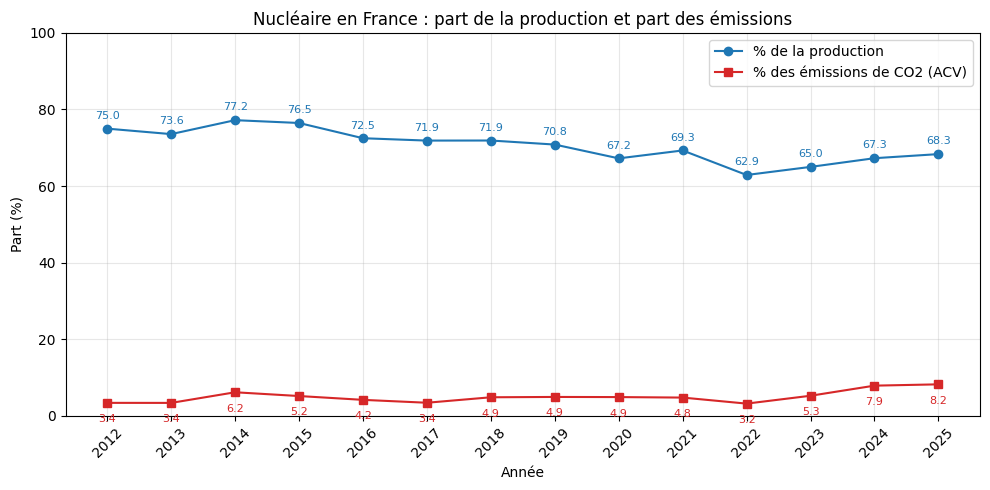

In [11]:
import matplotlib.pyplot as plt

p = percent_of_nuclear_per_year * 100
c = percent_of_nuclear_co2_per_year * 100

fig, ax = plt.subplots(figsize=(10, 5))
ax.plot(p.index, p.values, marker="o", color="tab:blue", label="% de la production")
ax.plot(c.index, c.values, marker="s", color="tab:red", label="% des émissions de CO2 (ACV)")

for x, y in zip(p.index, p.values):
    ax.annotate(f"{y:.1f}", (x, y), textcoords="offset points", xytext=(0, 7), ha="center", fontsize=8, color="tab:blue")
for x, y in zip(c.index, c.values):
    ax.annotate(f"{y:.1f}", (x, y), textcoords="offset points", xytext=(0, -14), ha="center", fontsize=8, color="tab:red")

ax.set_title("Nucléaire en France : part de la production et part des émissions")
ax.set_xlabel("Année")
ax.set_ylabel("Part (%)")
ax.set_xticks(p.index)
ax.set_xticklabels(p.index, rotation=45)
ax.set_ylim(0, 100)
ax.grid(alpha=0.3)
ax.legend()

plt.tight_layout()
plt.savefig("nucleaire_production_vs_co2.png", dpi=150)
plt.show()

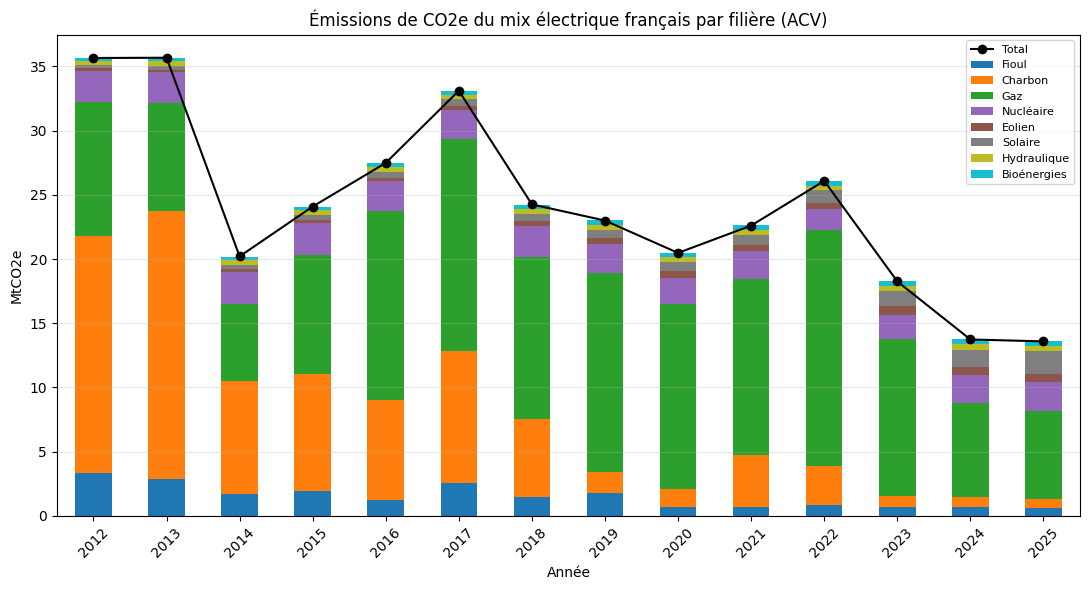

In [12]:
import matplotlib.pyplot as plt

# Tableau en MtCO2e, plus lisible
tab = (co2_t / 1e6).round(2)
tab.columns = [c.replace(" (kWh)", "") for c in tab.columns]
# print(tab)

# Barres empilées par filière
filieres = tab.drop(columns="Total (tCO2e)")
ax = filieres.plot(kind="bar", stacked=True, figsize=(11, 6), colormap="tab10")
ax.plot(range(len(tab)), tab["Total (tCO2e)"].values, color="black", marker="o", label="Total")
ax.set_title("Émissions de CO2e du mix électrique français par filière (ACV)")
ax.set_xlabel("Année")
ax.set_ylabel("MtCO2e")
ax.set_xticklabels(tab.index.astype(int), rotation=45)
ax.grid(axis="y", alpha=0.3)
ax.legend(loc="upper right", fontsize=8)
plt.tight_layout()
plt.savefig("co2_par_filiere.png", dpi=150)
plt.show()

In [13]:
co2_t

,Fioul (kWh),Charbon (kWh),Gaz (kWh),Nucléaire (kWh),Eolien (kWh),Solaire (kWh),Hydraulique (kWh),Bioénergies (kWh),Total (tCO2e)
Annee,,,,,,,,,
2012,3317256.145,1.845766e+07,1.046662e+07,2427326.151,193735.2820,2.080546e+05,380168.919,210112.488,3.566093e+07
2013,2902660.675,2.086996e+07,8.358834e+06,2420816.952,206860.4005,2.500579e+05,447902.367,223265.862,3.568036e+07
2014,1741042.700,8.798085e+06,5.960425e+06,2493026.286,221766.6685,3.200399e+05,404161.554,270361.188,2.020891e+07
2015,1937529.135,9.109316e+06,9.235109e+06,2498726.085,274225.4840,4.007483e+05,351130.077,284987.268,2.409177e+07
2016,1257466.975,7.725728e+06,1.478403e+07,2302225.482,271932.6025,4.543451e+05,380157.399,313609.140,2.748949e+07
2017,2539340.040,1.029989e+07,1.652807e+07,2273317.431,313268.4750,4.946512e+05,318082.098,339790.590,3.310641e+07
2018,1499779.890,6.082614e+06,1.262023e+07,2357900.838,365701.4270,5.820541e+05,404459.523,343655.370,2.425639e+07
2019,1747706.505,1.644799e+06,1.552025e+07,2275378.302,439608.8515,6.656194e+05,357012.834,347785.416,2.299816e+07
2020,676837.385,1.442020e+06,1.440782e+07,2011248.120,516103.6790,6.852461e+05,388837.536,348432.732,2.047654e+07


In [14]:
annee = 2017

p = percent_per_year.loc[annee]
gaz_charbon = p["Gaz (kWh)"] + p["Charbon (kWh)"]
nucleaire = p["Nucléaire (kWh)"]
facteur = nucleaire / gaz_charbon

# Part des émissions en 2017, avec le total déjà présent dans co2_t
total_co2 = co2_t.loc[annee, "Total (tCO2e)"]
charbon_co2 = co2_t.loc[annee, "Charbon (kWh)"] / total_co2 * 100
gaz_co2 = co2_t.loc[annee, "Gaz (kWh)"] / total_co2 * 100
gaz_charbon_co2 = charbon_co2 + gaz_co2

print(f"En {annee}, le gaz et le charbon représentent {gaz_charbon:.2f} % de la production.")
print(f"Le nucléaire en {annee} représente {100*nucleaire:.2f} % de la production.")
print(f"Le nucléaire a donc produit {facteur:.2f} fois plus d'énergie qu'eux.")
print(f"Pourtant, le gaz et le charbon représentent {gaz_charbon_co2:.2f} % des émissions de CO2 "
      f"(gaz : {gaz_co2:.2f} %, charbon : {charbon_co2:.2f} %).")

En 2017, le gaz et le charbon représentent 0.09 % de la production.
Le nucléaire en 2017 représente 71.87 % de la production.
Le nucléaire a donc produit 7.69 fois plus d'énergie qu'eux.
Pourtant, le gaz et le charbon représentent 81.04 % des émissions de CO2 (gaz : 49.92 %, charbon : 31.11 %).


In [15]:
percent_per_year

,Fioul (kWh),Charbon (kWh),Gaz (kWh),Nucléaire (kWh),Eolien (kWh),Solaire (kWh),Hydraulique (kWh),Bioénergies (kWh)
Annee,,,,,,,,
2012,0.008423,0.032339,0.046416,0.749914,0.027625,0.007012,0.117452,0.010819
2013,0.007250,0.035965,0.036459,0.735614,0.029012,0.008289,0.136104,0.011307
2014,0.004431,0.015451,0.026494,0.772008,0.031696,0.010812,0.125155,0.013954
2015,0.004873,0.015809,0.040566,0.764655,0.038731,0.013378,0.107452,0.014535
2016,0.003254,0.013795,0.066815,0.724863,0.039516,0.015606,0.119694,0.016457
2017,0.006598,0.018466,0.075004,0.718698,0.045710,0.017060,0.100560,0.017904
2018,0.003758,0.010517,0.055231,0.718896,0.051461,0.019359,0.123315,0.017463
2019,0.004472,0.002904,0.069351,0.708325,0.063162,0.022604,0.111138,0.018044
2020,0.001860,0.002734,0.069129,0.672284,0.079622,0.024987,0.129974,0.019411


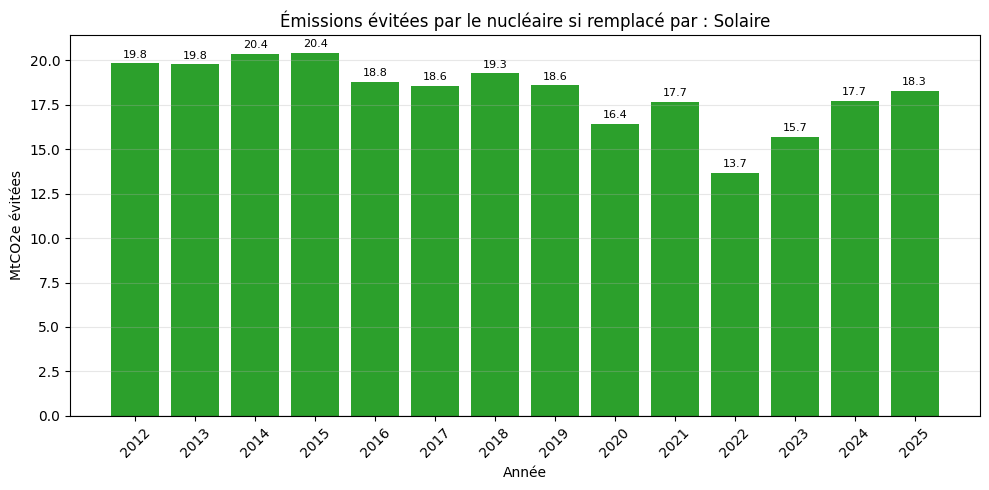

In [16]:
import matplotlib.pyplot as plt

sub = "Solaire (kWh)"
evite = kwh["Nucléaire (kWh)"] * (fe[sub] - fe["Nucléaire (kWh)"]) / 1e6   # tCO2e
evite_mt = evite / 1e6                                                      # MtCO2e

fig, ax = plt.subplots(figsize=(10, 5))
couleurs = ["tab:green" if v >= 0 else "tab:red" for v in evite_mt.values]
ax.bar(evite_mt.index.astype(int), evite_mt.values, color=couleurs)

for x, y in zip(evite_mt.index.astype(int), evite_mt.values):
    ax.annotate(f"{y:.1f}", (x, y), textcoords="offset points",
                xytext=(0, 4 if y >= 0 else -12), ha="center", fontsize=8)

ax.axhline(0, color="black", linewidth=0.8)
ax.set_title(f"Émissions évitées par le nucléaire si remplacé par : {sub.replace(' (kWh)', '')}")
ax.set_xlabel("Année")
ax.set_ylabel("MtCO2e évitées")
ax.set_xticks(evite_mt.index.astype(int))
ax.set_xticklabels(evite_mt.index.astype(int), rotation=45)
ax.grid(axis="y", alpha=0.3)

plt.tight_layout()
plt.savefig("emissions_evitees.png", dpi=150)
plt.show()

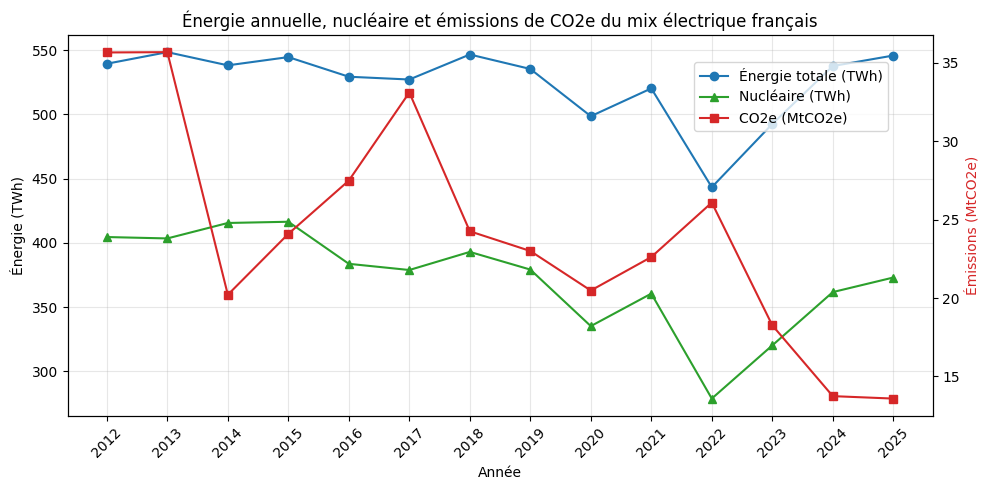

In [18]:
import matplotlib.pyplot as plt

energie = kwh.sum(axis=1) / 1e9               # TWh
nucleaire = kwh["Nucléaire (kWh)"] / 1e9      # TWh
co2 = co2_t["Total (tCO2e)"] / 1e6            # MtCO2e

fig, ax1 = plt.subplots(figsize=(10, 5))

ax1.plot(energie.index, energie.values, marker="o", color="tab:blue", label="Énergie totale (TWh)")
ax1.plot(nucleaire.index, nucleaire.values, marker="^", color="tab:green", label="Nucléaire (TWh)")
ax1.set_xlabel("Année")
ax1.set_ylabel("Énergie (TWh)")
ax1.set_xticks(energie.index)
ax1.set_xticklabels(energie.index, rotation=45)
ax1.grid(alpha=0.3)

ax2 = ax1.twinx()
ax2.plot(co2.index, co2.values, marker="s", color="tab:red", label="CO2e (MtCO2e)")
ax2.set_ylabel("Émissions (MtCO2e)", color="tab:red")

plt.title("Énergie annuelle, nucléaire et émissions de CO2e du mix électrique français")
fig.legend(loc="upper right", bbox_to_anchor=(0.9, 0.88))
plt.tight_layout()
plt.savefig("Énergie_nucléaire_émissions.png", dpi=150)
plt.show()